# MESA to GYRE oscillation walkthrough

This notebook exercises the reusable pipeline without copying its implementation. It validates a MESA GYRE-format pulse model, constructs the namelist, optionally runs GYRE, and inspects the mode summary and eigenfunctions.

## Expected artifacts

The input model may live anywhere. The run directory under `results/run_gyre/` receives `gyre.in`, a copied model, metadata, the solver log, `summary.h5`, `modes.csv`, and one `detail.l*.n*.h5` file per saved mode. Run this notebook from the repository root.

In [2]:
from pathlib import Path

import os

os.environ["GYRE_DIR"] = "/Users/mchau/gyre-9.1.1"

# Edit these parameters. MODEL_PATH must be a MESA pulse file written
# with pulse_data_format = 'GYRE', not an ordinary profile*.data file.
MODEL_PATH = Path(
    '/Users/mchau/mesa_tutorial/results/mams_profiles/'
    'ZAMS8Msun_Z0p0142/'
    'ZAMS8Msun_Z0p0142.mesa'
)
PROJECT_ROOT = Path('/Users/mchau/mesa_tutorial/mesa-gyre-oscillations')

OUTPUT_DIR = (
    PROJECT_ROOT
    / 'results'
    / 'run_gyre'
    / MODEL_PATH.stem
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
GYRE_EXECUTABLE = Path('/Users/mchau/gyre-9.1.1/bin/gyre')  # Example: Path('/path/to/gyre/bin/gyre')
RUN_GYRE = True        # Change to True when the configuration is ready.

HARMONIC_DEGREES = (2,)

N_PG_MIN, N_PG_MAX = -20, 20

FREQ_MIN = 0.01
FREQ_MAX = 50
N_FREQ = 50000

SCAN_FREQ_UNITS = 'NONE'
OUTPUT_FREQ_UNITS = 'CYC_PER_DAY'

GRID_TYPE = 'INVERSE'
THREADS = 1

In [3]:
import csv
import sys
import numpy as np
import matplotlib.pyplot as plt

def find_repo_root(start):
    for candidate in (start, *start.parents):
        module = candidate / 'scripts' / 'run_gyre' / 'pipeline' / 'gyre_pipeline.py'
        if module.is_file():
            return candidate
    raise FileNotFoundError('Run this notebook from inside the cloned repository.')

repo_root = find_repo_root(Path.cwd().resolve())
pipeline_dir = repo_root / 'scripts' / 'run_gyre' / 'pipeline'
if str(pipeline_dir) not in sys.path:
    sys.path.insert(0, str(pipeline_dir))
if not MODEL_PATH.is_absolute():
    MODEL_PATH = repo_root / MODEL_PATH
if not OUTPUT_DIR.is_absolute():
    OUTPUT_DIR = repo_root / OUTPUT_DIR

from gyre_pipeline import (
    RunConfig, load_gyre_hdf5, load_summary, render_gyre_input,
    run_pipeline, validate_model_file,
)

plt.rcParams.update({
    'font.size': 16,
    'axes.labelsize': 20,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 15,
    'axes.titlesize': 0,
    'lines.linewidth': 2.2,
    'lines.markersize': 6,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'mathtext.fontset': 'stix',
    'font.family': 'STIXGeneral',
})

## 1. Validate the stellar model

This inexpensive check catches missing files and ordinary MESA profile tables before GYRE is launched.

In [4]:
MODEL_AVAILABLE = MODEL_PATH.is_file()
if MODEL_AVAILABLE:
    model_info = validate_model_file(MODEL_PATH)
    model_info
else:
    print(
        f'Model not found: {MODEL_PATH}\n'
        'Copy a MESA GYRE-format pulse file there or edit MODEL_PATH, '
        'then rerun this cell.'
    )

## 2. Build and inspect the GYRE configuration

The scan bounds and output units are independent. Here the scan uses dimensionless angular frequency while the output frequency column uses cycles per day.

In [5]:
config = RunConfig(
    harmonic_degrees=HARMONIC_DEGREES,
    n_pg_min=N_PG_MIN,
    n_pg_max=N_PG_MAX,
    freq_min=FREQ_MIN,
    freq_max=FREQ_MAX,
    n_freq=N_FREQ,
    freq_units=SCAN_FREQ_UNITS,
    output_freq_units=OUTPUT_FREQ_UNITS,
    grid_type=GRID_TYPE,
    threads=THREADS,
)
print(render_gyre_input(config))

&constants
/

&model
  model_type = 'EVOL'
  file = 'input_model.mesa'
  file_format = 'MESA'
/

&mode
  l = 2
  n_pg_min = -20
  n_pg_max = 20
/

&osc
  outer_bound = 'VACUUM'
/

&rot
/

&num
  diff_scheme = 'COLLOC_GL4'
/

&scan
  grid_type = 'INVERSE'
  freq_min = 0.01
  freq_max = 50
  n_freq = 50000
  freq_units = 'NONE'
/

&grid
  w_osc = 10
  w_exp = 2
  w_ctr = 10
/

&ad_output
  summary_file = 'summary.h5'
  summary_item_list = 'l,n_pg,n_p,n_g,omega,freq,E_norm,R_star,M_star'
  detail_template = 'detail.l%l.n%n.h5'
  detail_item_list = 'l,n_pg,omega,x,xi_r,xi_h,c_1,As,V_2,Gamma_1,rho,M_r'
  freq_units = 'CYC_PER_DAY'
/

&nad_output
/



## 3. Prepare a dry run

The first execution creates the portable model copy, `gyre.in`, and metadata without requiring a GYRE installation. An existing run directory is preserved.

In [6]:
if MODEL_AVAILABLE and not OUTPUT_DIR.exists():
    preview = run_pipeline(
        MODEL_PATH, OUTPUT_DIR, config, dry_run=True, overwrite=False
    )
    print(f'Prepared {preview.output_dir}')
elif OUTPUT_DIR.exists():
    print(f'Preserving existing run directory: {OUTPUT_DIR}')
else:
    print('Dry run skipped until MODEL_PATH is available.')

Preserving existing run directory: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/ZAMS8Msun_Z0p0142


## 4. Optional end-to-end calculation

Set `RUN_GYRE = True` in the parameter cell after reviewing the namelist. This replaces the dry-run directory with the complete calculation.

In [7]:
if RUN_GYRE and MODEL_AVAILABLE:
    result = run_pipeline(
        MODEL_PATH,
        OUTPUT_DIR,
        config,
        gyre_executable=GYRE_EXECUTABLE,
        overwrite=True,
        dry_run=False,
    )
    print(f'Completed: {result.output_dir}')
elif RUN_GYRE:
    print('GYRE run skipped because MODEL_PATH is unavailable.')
else:
    print('GYRE run disabled. Set RUN_GYRE = True when ready.')

Completed: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/ZAMS8Msun_Z0p0142


## 5. Inspect the mode catalogue

modes.csv` is convenient for collaborators and spreadsheets; `summary.h5` retains the native GYRE arrays and metadata.

In [8]:
summary_path = OUTPUT_DIR / 'summary.h5'
csv_path = OUTPUT_DIR / 'modes.csv'
if summary_path.is_file():
    summary = load_summary(summary_path)
    print(f"Modes found: {len(summary.get('l', []))}")
    print(f"Frequency units: {summary['_attrs'].get('freq_units', 'unknown')}")
    if csv_path.is_file():
        with csv_path.open(newline='', encoding='utf-8') as stream:
            rows = list(csv.DictReader(stream))
        rows[:10]
else:
    print('No summary.h5 yet; complete a real GYRE run first.')

Modes found: 42
Frequency units: unknown


## 6. Plot one eigenfunction

The first detail file is used as a compact example. Select another file to inspect a particular `(l, n_pg)` mode. The figure is saved in both PDF and PNG formats in the run directory.

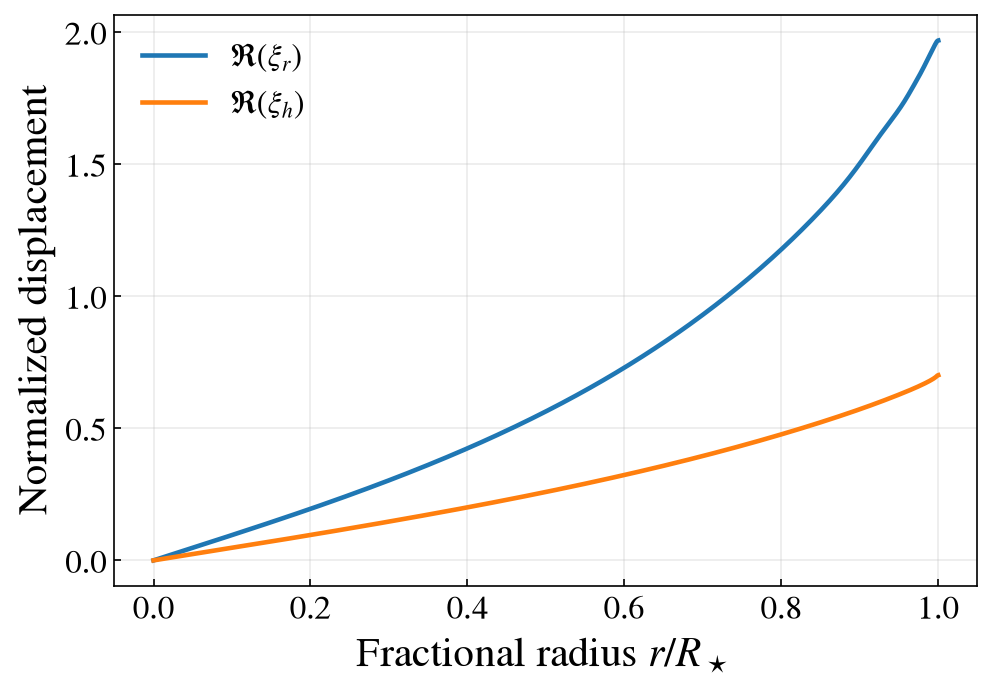

In [9]:
detail_files = sorted(OUTPUT_DIR.glob('detail.l*.n*.h5'))
if detail_files:
    detail = load_gyre_hdf5(detail_files[0])
    radius = np.asarray(detail['x'])
    xi_r = np.abs(np.asarray(detail['xi_r']))
    xi_h = np.abs(np.asarray(detail['xi_h']))

    fig, ax = plt.subplots(figsize=(6.5, 4.5), constrained_layout=True)
    ax.plot(radius, xi_r, label=r'$\Re(\xi_r)$')
    ax.plot(radius, xi_h, label=r'$\Re(\xi_h)$')
    ax.set_xlabel(r'Fractional radius $r/R_\star$')
    ax.set_ylabel(r'Normalized displacement')
    ax.tick_params(which='both', direction='in')
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    fig.savefig(OUTPUT_DIR / 'eigenfunctions.pdf', bbox_inches='tight')
    fig.savefig(OUTPUT_DIR / 'eigenfunctions.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print('No detail files yet; complete a real GYRE run first.')

## Interpretation

The mode table gives the radial-order classification and eigenfrequency. The detail files contain the radial dependence of the displacement eigenfunctions. Mode completeness depends on the chosen scan interval and resolution, so a production calculation should be checked by widening the interval and increasing `N_FREQ`.

n_pg: [-20 -19 -18  -4 -17 -16 -15 -14 -13 -12 -11 -10  -9  -8  -7  -6  -5  -4
  -3  -2  -1   0   1   2   3   4   5   6   7   8   9  10  11  12  13  14
  15  16  17  18  19  20]
Dimensionless omega: [1.03106252e-02 1.08361141e-02 1.14182944e-02 1.16524408e-02
 1.20665595e-02 1.27924357e-02 1.36107359e-02 1.45410326e-02
 1.56091386e-02 1.68474892e-02 1.82988926e-02 2.00207131e-02
 2.20972286e-02 2.46538905e-02 2.78836786e-02 3.20808659e-02
 3.77714228e-02 4.58977850e-02 5.84284218e-02 8.02469697e-02
 1.27138340e-01 1.52587292e+00 3.24283279e+00 4.71229905e+00
 6.14416822e+00 7.46257040e+00 8.73824149e+00 1.01704702e+01
 1.15200119e+01 1.28776730e+01 1.43087628e+01 1.57377988e+01
 1.71443296e+01 1.85440047e+01 1.99626145e+01 2.13852742e+01
 2.28112874e+01 2.42415166e+01 2.56643861e+01 2.70847998e+01
 2.85119661e+01 2.99410544e+01]
Frequency (cycles/day): [4.10724142e-04 4.31657011e-04 4.54848187e-04 4.64175416e-04
 4.80671852e-04 5.09587157e-04 5.42184174e-04 5.79242578e-04
 6.21790623e-

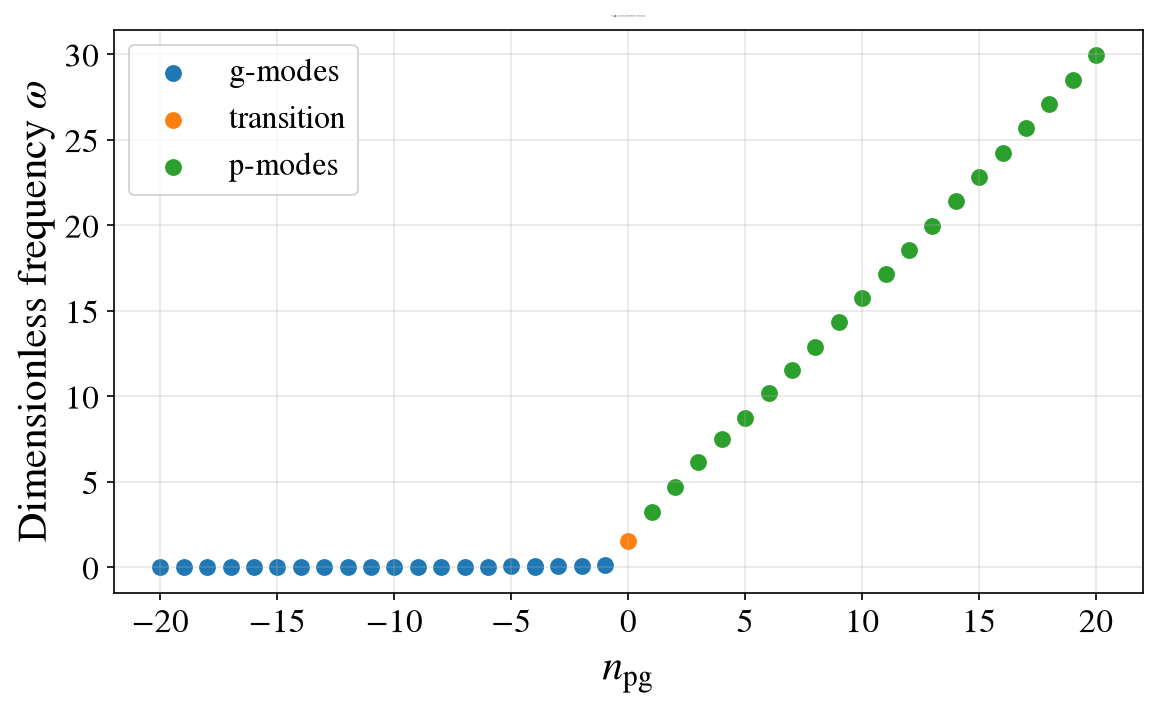

In [10]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

SUMMARY = Path(
    "/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/"
    "results/run_gyre/ZAMS8Msun_Z0p0142/summary.h5"
)

with h5py.File(SUMMARY, "r") as f:
    n_pg = f["n_pg"][:]
    omega = f["omega"]["re"][:]
    freq = f["freq"]["re"][:]

print("n_pg:", n_pg)
print("Dimensionless omega:", omega)
print("Frequency (cycles/day):", freq)

# Identify modes
g_modes = n_pg < 0
p_modes = n_pg > 0
transition = n_pg == 0

fig, ax = plt.subplots(figsize=(8, 5))

# g-modes
ax.scatter(
    n_pg[g_modes],
    omega[g_modes],
    s=50,
    label="g-modes"
)

# Transition modes
ax.scatter(
    n_pg[transition],
    omega[transition],
    s=50,
    label="transition"
)

# p-modes
ax.scatter(
    n_pg[p_modes],
    omega[p_modes],
    s=50,
    label="p-modes"
)

ax.set_xlabel(r"$n_{\rm pg}$")
ax.set_ylabel(r"Dimensionless frequency $\omega$")
ax.set_title(r"1 M$_\odot$ MAMS Eigenfrequency Spectrum")

ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()